# Phase 5 — Hawkes-Driven Avellaneda–Stoikov Market Maker
### Hawkes-Process-Driven Market Making · LOBSTER AAPL 2012-06-21

This capstone couples the **self-exciting Hawkes intensity** (Phases 1–3) to the **Avellaneda–Stoikov**
quoting model (Phase 4). Throughout we are scrupulous about *provenance* — every result is tagged:

| tag | meaning |
|---|---|
| **[AS-EXACT]** | an exact result of Avellaneda & Stoikov (2008) |
| **[HAWKES]** | a standard Hawkes-process result (Phases 2–3) |
| **[APPROX]** | an approximation introduced by this project (never claimed exact) |
| **[CONTRIBUTION]** | the project's original idea |

The headline discipline: **we do not blindly replace $\kappa$ by $\lambda(t)$** — they have different
units and meaning. We *derive and justify* an intensity-modulated approximation instead, and we
distinguish what survives the move to Hawkes arrivals from what becomes an approximation.

The notebook uses the deliverable modules (`market_maker/`, `analysis/`) and loads the full results
produced by `python -m analysis.comparison`.

---
## 0. Setup

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display

from market_maker import ASParameters
from market_maker.hawkes_execution import HawkesIntensity, SidedHawkes, intensity_on_grid
from market_maker.hawkes_market_maker import PoissonASPolicy, HawkesASPolicy
from market_maker.historical_replay import (generate_synthetic_events, run_backtest,
                                            load_lobster_events)
from analysis.comparison import compute_metrics, make_sided
from analysis import stat_tests

sns.set_theme(context="notebook", style="whitegrid")
PLOTS="../plots/hawkes_market_maker"; RESULTS="../results"
DATA="../LOBSTER_SampleFile_AAPL_2012-06-21_10/AAPL_2012-06-21_34200000_57600000_"
sp = json.load(open(f"{RESULTS}/hawkes_side_params.json"))
params = ASParameters(gamma=0.1, sigma=0.03477, kappa=23.96, A=1.445, T=600.0, q_max=50)
print("per-side Hawkes (buy/sell):")
for s in ("buy","sell"):
    print(f"  {s}: mu={sp[s]['mu']:.3f} alpha={sp[s]['alpha']:.1f} beta={sp[s]['beta']:.1f} "
          f"rho={sp[s]['rho']:.3f} lam_bar={sp[s]['lam_bar']:.3f}")

per-side Hawkes (buy/sell):
  buy: mu=0.271 alpha=187.0 beta=405.7 rho=0.461 lam_bar=0.503
  sell: mu=0.310 alpha=161.6 beta=363.5 rho=0.445 lam_bar=0.559


## Part 1 — Where the Poisson assumption enters the AS HJB equation

With CARA utility and Poisson order flow of intensity $\lambda(\delta)=Ae^{-\kappa\delta}$, the AS
value function $u(x,s,q,t)$ solves the HJB equation

$$u_t+\tfrac12\sigma^2u_{ss}+\max_{\delta^b}\lambda^b(\delta^b)[u(x-s+\delta^b,s,q{+}1,t)-u]+\max_{\delta^a}\lambda^a(\delta^a)[u(x+s+\delta^a,s,q{-}1,t)-u]=0.$$

The two $\lambda(\delta)[u(\cdot)-u]$ terms are the **generator of a Poisson jump process**. The
Poisson assumption enters through **two properties**:

1. the intensity depends only on the *control* $\delta$, not on trade history → the problem is
   **Markovian** in $(x,s,q,t)$;
2. the closed arrival law $Ae^{-\kappa\delta}$ makes the inner maximisation explicit, yielding
   $r=S-q\gamma\sigma^2(T-t)$ **[AS-EXACT]** and $\delta^*=\gamma\sigma^2(T-t)+\tfrac2\gamma\ln(1+\tfrac\gamma\kappa)$ **[AS-EXACT]**.

Under **Hawkes** arrivals $\lambda(t)=\mu+\alpha\sum_{t_i<t}e^{-\beta(t-t_i)}$ is *stochastic and
history-dependent* **[HAWKES]** → the state is no longer Markovian, and the HJB gains an extra
dimension with **no closed-form solution**.

| ingredient | under Hawkes |
|---|---|
| reservation price $r=S-q\gamma\sigma^2(T-t)$ | **remains [AS-EXACT]** (inventory risk, not arrivals) |
| inventory-risk spread $\gamma\sigma^2(T-t)$ | **remains [AS-EXACT]** |
| microstructure spread $\tfrac2\gamma\ln(1+\tfrac\gamma\kappa)$ | **becomes [APPROX]** (derived for constant $\kappa$) |
| value function / optimality | **lost** — our policy is a justified heuristic |

The full derivation is Section 1 of `reports/hawkes_extension_report.md`.

## Part 2 — Hawkes intensity vs trade arrivals [HAWKES]

Using the calibrated buy-side parameters we compute $\lambda_{buy}(t)$ over a window of the **real
LOBSTER** trade stream and overlay the actual arrivals. Intensity spikes exactly during order-flow
clusters.

In [2]:
lob = load_lobster_events(DATA)
buy_times = lob[lob.side=="buy"]["time"].to_numpy()
w0, w1 = 1000.0, 1090.0                       # a 90-second window
grid = np.linspace(w0, w1, 4000)
lam = intensity_on_grid(grid, buy_times, sp["buy"]["mu"], sp["buy"]["alpha"], sp["buy"]["beta"])
ev_win = buy_times[(buy_times>=w0)&(buy_times<=w1)]
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(grid, lam, color="green", lw=0.7, label=r"$\lambda_{buy}(t)$")
ax.axhline(sp["buy"]["lam_bar"], color="black", ls="--", lw=1, label=r"$\bar\lambda_{buy}$")
ax.plot(ev_win, np.full_like(ev_win, -3), "|", color="red", ms=8, label="buy trades")
ax.set(xlabel="time (s)", ylabel="intensity (events/s)", ylim=(-6, lam.max()*1.05),
       title="Hawkes intensity spikes during clustered buy arrivals (real LOBSTER)")
ax.legend(loc="upper right"); plt.show()
print(f"lambda_buy: baseline {sp['buy']['lam_bar']:.2f}/s, peak in window {lam.max():.1f}/s "
      f"({lam.max()/sp['buy']['lam_bar']:.0f}x baseline)")

lambda_buy: baseline 0.50/s, peak in window 127.6/s (254x baseline)


/var/folders/8y/qp00w7_52xs1hwsmd4s28f5c0000gn/T/ipykernel_10414/3709650885.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax.legend(loc="upper right"); plt.show()


**Why we quote on a *smoothed* intensity.** The instantaneous $\lambda(t)$ jumps by $\alpha\approx190$
at every event and decays on the sub-millisecond $1/\beta$ scale, so it is far too spiky to quote on.
A market maker reacts to activity over a **quote-reaction window** $h$; we use the Hawkes conditional
expectation $E[\lambda(u)\mid\mathcal F_t]$ over $h$ **[HAWKES]**, which is bounded and smooth. This is
computed by `HawkesIntensity.expected_rate`.

## Part 3 — Dynamic quote model [APPROX]

**We do NOT set $\kappa=\lambda(t)$** — $\kappa$ is a price-elasticity (1/\$) and $\lambda(t)$ a rate
(1/s); the substitution is dimensionally invalid and mis-scaled. Instead we modulate $\kappa$ by the
**dimensionless normalised intensity** $R(t)=\lambda_{exp}(t)/\bar\lambda$ (=1 on average):

$$\delta(t)=\gamma\sigma^2(T-t)+\frac2\gamma\ln\!\Big(1+\frac{\gamma R(t)}{\kappa}\Big)\qquad\textbf{[APPROX]}$$

At $R=1$ it reduces **exactly** to classical AS **[AS-EXACT]**; when activity spikes ($R>1$) it
widens. Below: the naive literal substitution blows the spread up ~10×, illustrating why the
normalisation is necessary.

In [3]:
from market_maker.hawkes_market_maker import _reservation
gamma, kappa = params.gamma, params.kappa
R = np.linspace(0.5, 8, 200); lam_bar = sp["buy"]["lam_bar"]+sp["sell"]["lam_bar"]
norm = gamma*params.sigma**2*300 + (2/gamma)*np.log(1+gamma*R/kappa)     # normalized (ours)
naive = gamma*params.sigma**2*300 + (2/gamma)*np.log(1+gamma/(R*lam_bar/2)) # literal kappa->lambda
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(R, norm, color="navy", lw=2); ax[0].axhline(norm[np.argmin(abs(R-1))], color="gray", ls=":")
ax[0].set(xlabel="R(t)=lambda/lam_bar", ylabel="spread ($)", title="Ours [APPROX]: widens smoothly with activity")
ax[1].plot(R, naive, color="crimson", lw=2)
ax[1].set(xlabel="R(t)", ylabel="spread ($)", title="Naive kappa->lambda(t): mis-scaled (~$ wide)")
plt.tight_layout(); plt.show()

/var/folders/8y/qp00w7_52xs1hwsmd4s28f5c0000gn/T/ipykernel_10414/2131482651.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## Part 4 — Buy/sell asymmetry [APPROX]

The **ask** reacts to **buy** intensity, the **bid** to **sell** intensity:

$$\delta_{ask}=\tfrac12\gamma\sigma^2(T{-}t)+\tfrac1\gamma\ln(1+\gamma R_{buy}/\kappa),\quad
\delta_{bid}=\tfrac12\gamma\sigma^2(T{-}t)+\tfrac1\gamma\ln(1+\gamma R_{sell}/\kappa).$$

*Economic reasoning:* a surge in **buy** market orders signals upward/informed pressure → make the
**ask less aggressive** (raise it) to avoid selling before a rise; symmetrically a sell surge makes
the **bid less aggressive**. This hedges adverse selection.

In [4]:
polB = HawkesASPolicy(params, sp["buy"]["lam_bar"], sp["sell"]["lam_bar"])
mid = 585.0
for (rb, rs, tag) in [(1,1,"balanced (R=1,1)"), (4,1,"BUY surge (R_buy=4)"), (1,4,"SELL surge (R_sell=4)")]:
    lb, ls = rb*sp["buy"]["lam_bar"], rs*sp["sell"]["lam_bar"]
    q = polB.quote(mid, q=0, t=0.0, lam_buy=lb, lam_sell=ls)
    print(f"{tag:22s}: bid={q.bid:.3f} (d={mid-q.bid:.3f})  ask={q.ask:.3f} (d={q.ask-mid:.3f})  spread={q.spread:.3f}")
print("\n-> a buy surge pushes the ASK out (less aggressive); a sell surge pushes the BID out.")

balanced (R=1,1)      : bid=584.922 (d=0.078)  ask=585.078 (d=0.078)  spread=0.156
BUY surge (R_buy=4)   : bid=584.922 (d=0.078)  ask=585.202 (d=0.202)  spread=0.280
SELL surge (R_sell=4) : bid=584.798 (d=0.202)  ask=585.078 (d=0.078)  spread=0.280

-> a buy surge pushes the ASK out (less aggressive); a sell surge pushes the BID out.


## Part 5 — Event-driven simulator: one Hawkes-MM episode

At every event: update intensities → recompute reservation, spread, bid, ask → generate fills →
update inventory, cash, PnL. Figures 1–6 (saved by the analysis module):

events=621 fills=139 terminalPnL=$7.59 invVar=1.96 avgSpread=$0.1413


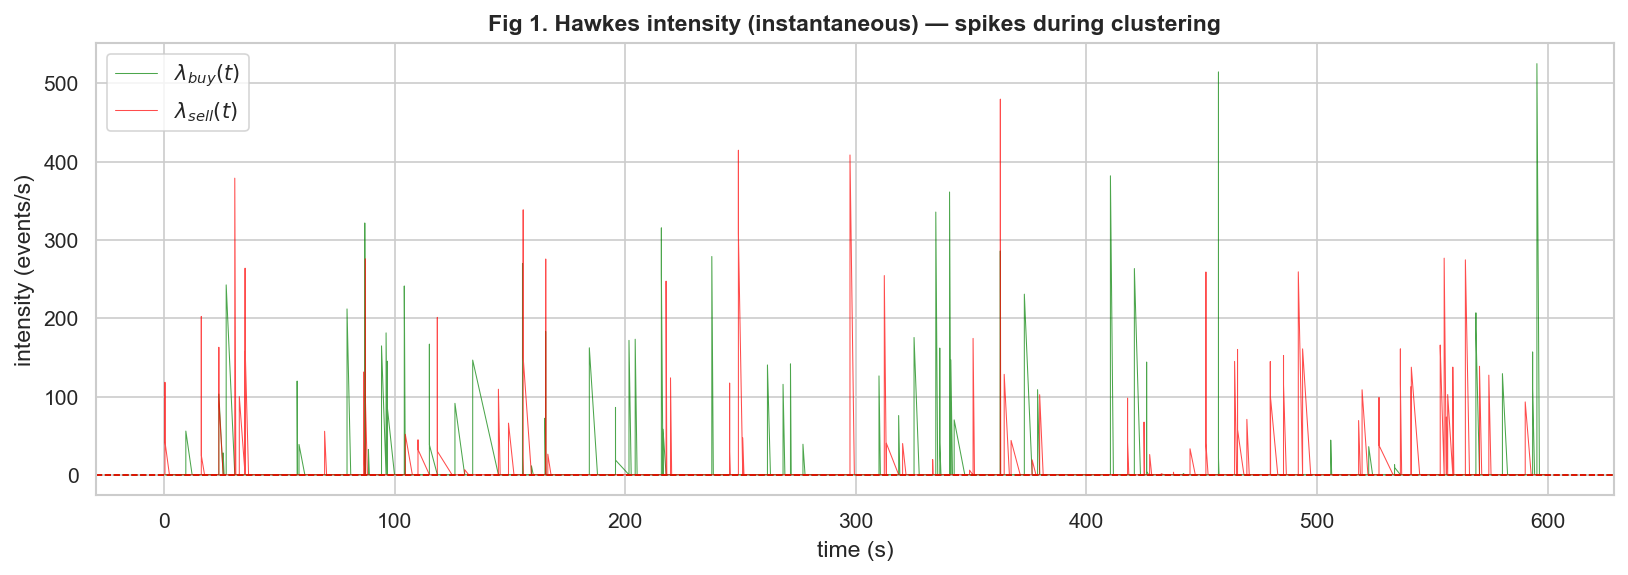

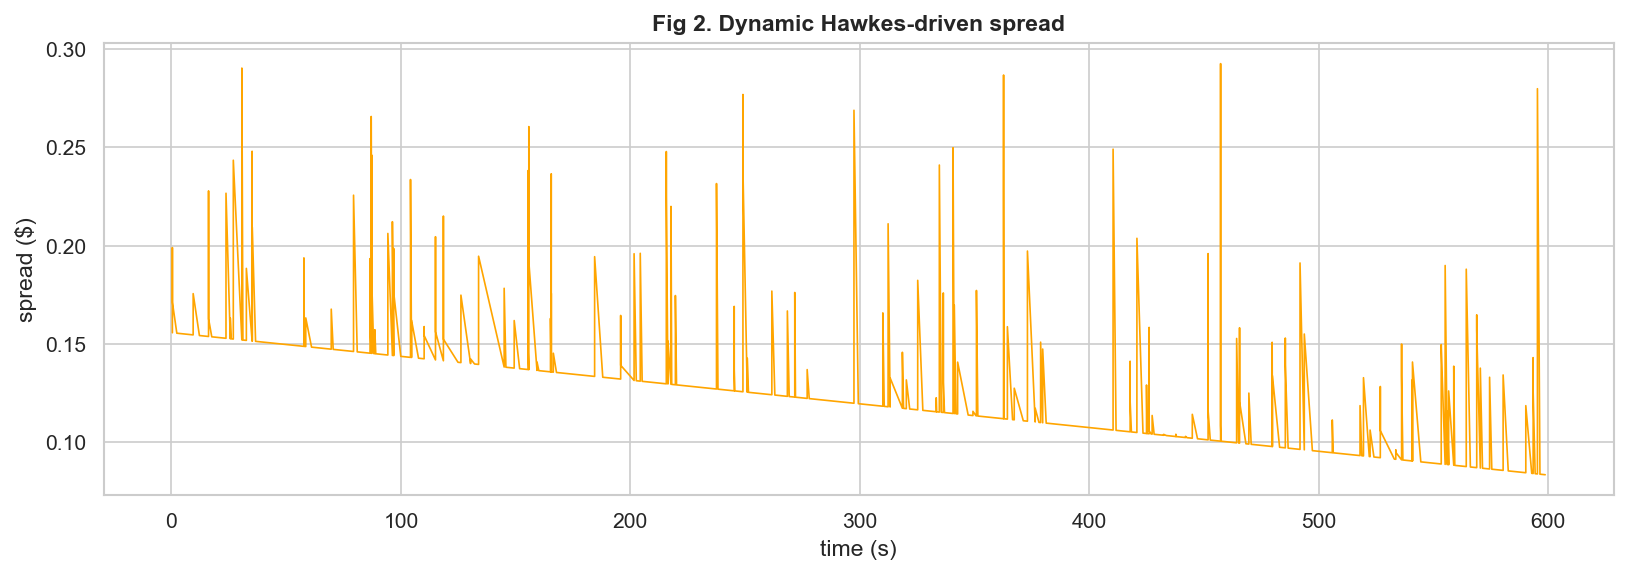

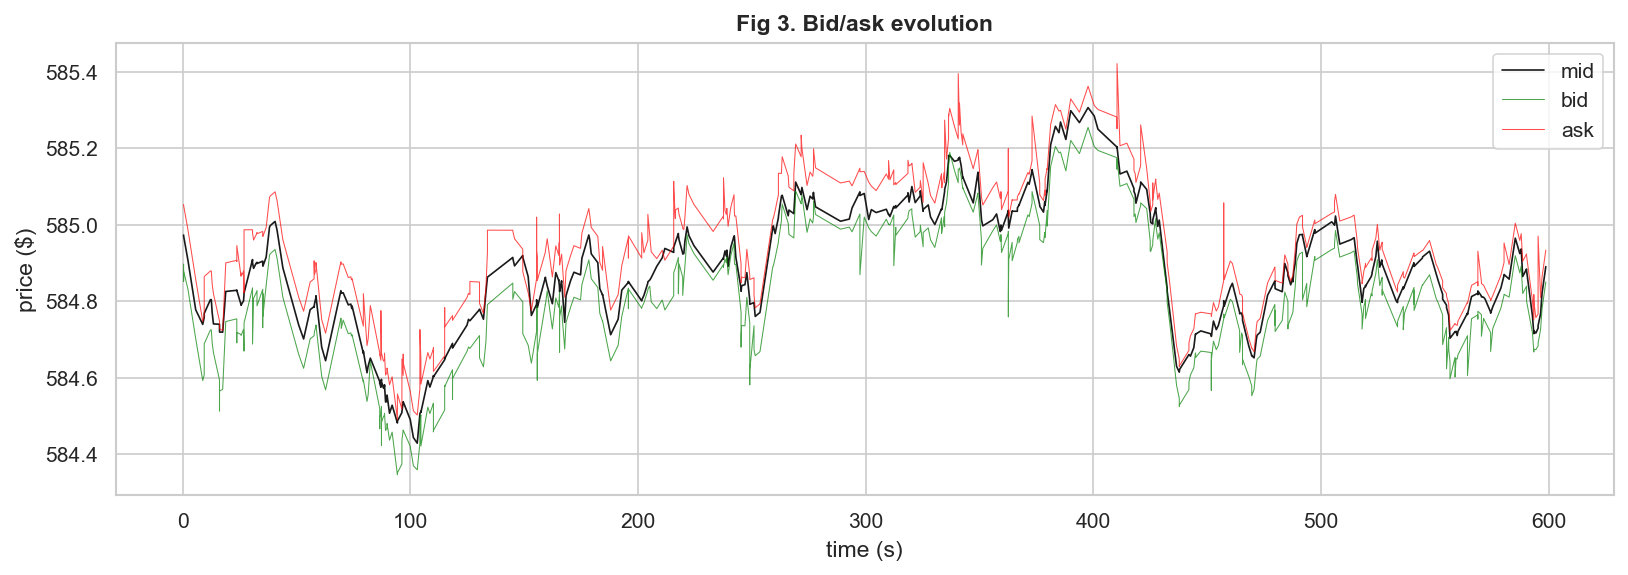

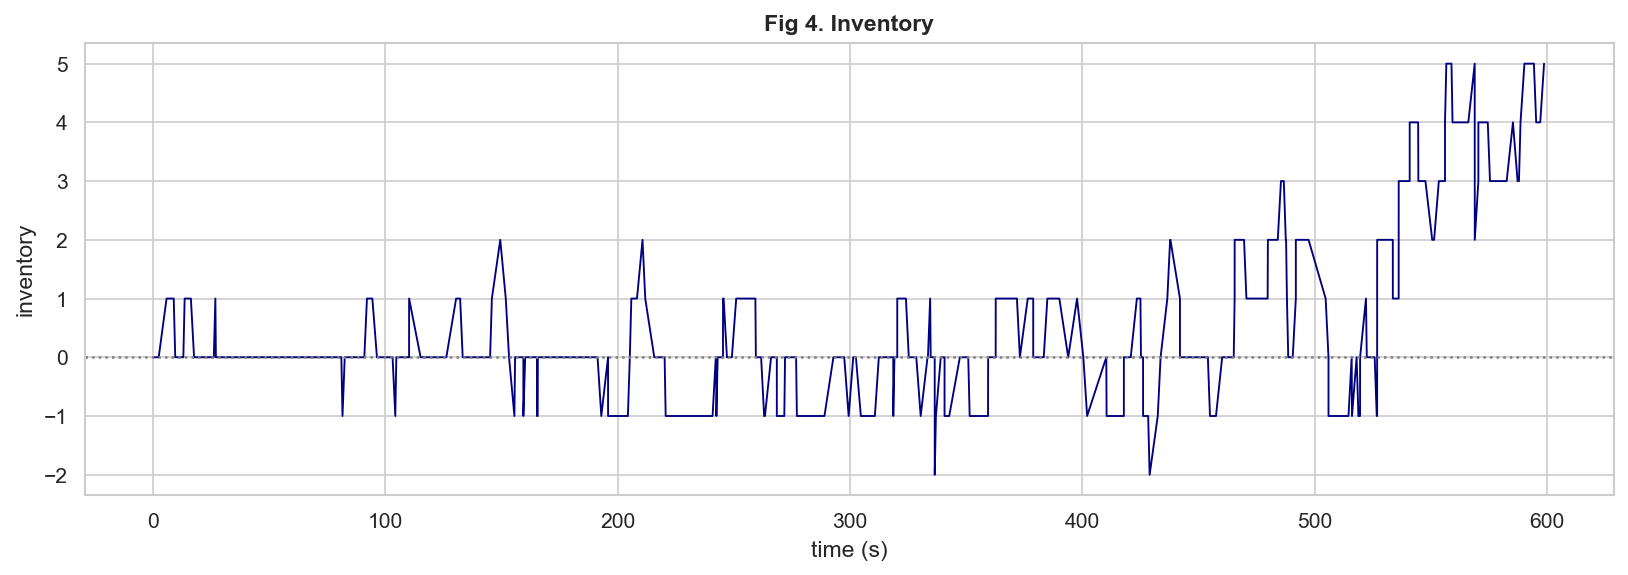

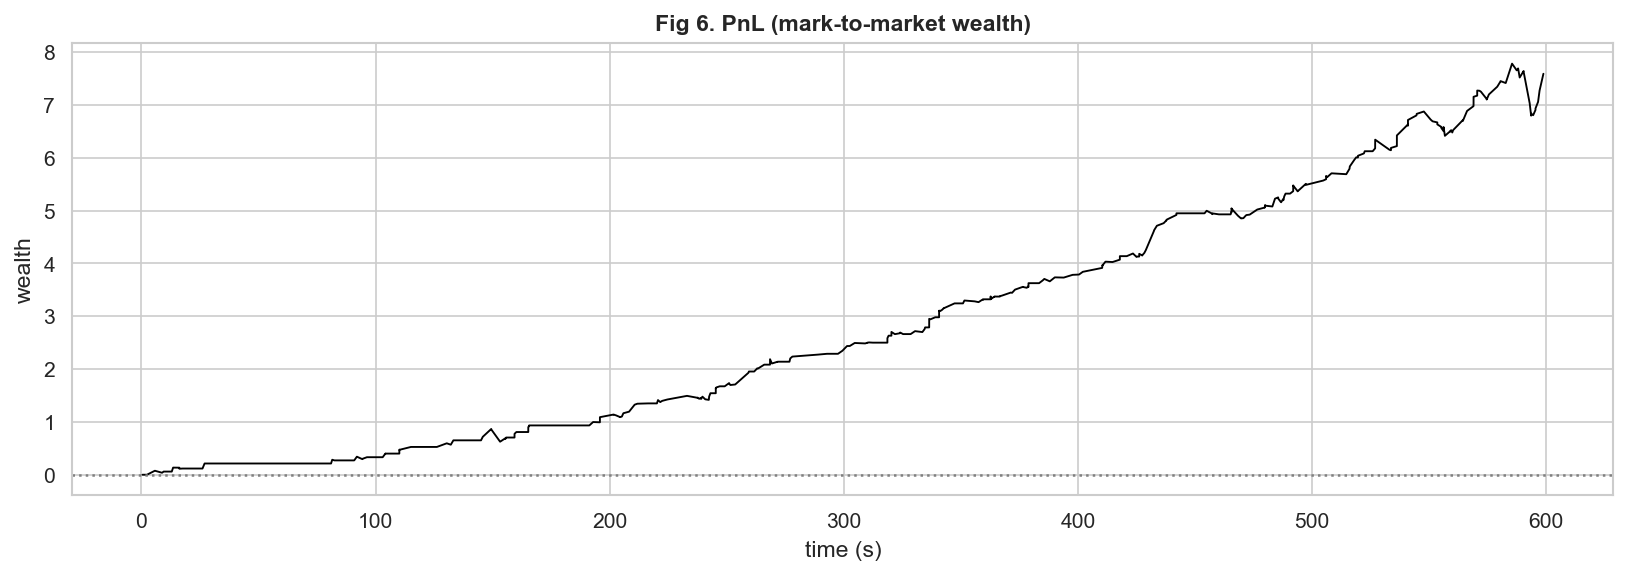

In [5]:
buy = HawkesIntensity(sp["buy"]["mu"], sp["buy"]["alpha"], sp["buy"]["beta"])
sell = HawkesIntensity(sp["sell"]["mu"], sp["sell"]["alpha"], sp["sell"]["beta"])
ev = generate_synthetic_events(buy, sell, 600.0, seed=7)
res = run_backtest(ev, polB, make_sided(sp), params, label="Hawkes", synthetic=True,
                   impact=0.002, s0=585.0, seed=1007)
print(f"events={len(ev)} fills={len(res.fills)} terminalPnL=${res.terminal_wealth:.2f} "
      f"invVar={res.history.inventory.var():.2f} avgSpread=${res.history.spread.mean():.4f}")
for f in ["fig01_intensity.png","fig02_dynamic_spread.png","fig03_bid_ask.png",
          "fig04_inventory.png","fig06_pnl.png"]:
    display(Image(filename=f"{PLOTS}/{f}"))

## Part 6 — Historical replay (real LOBSTER stream)

We replay the actual event stream and ask *"would my quotes have executed?"* — a resting quote is
filled if a market order trades through it (crossing rule; queue position ignored **[APPROX]**, so
fill rates are an optimistic upper bound).

In [6]:
pr = ASParameters(gamma=params.gamma, sigma=params.sigma, kappa=params.kappa,
                  A=params.A, T=float(lob.time.max()), q_max=params.q_max)
rep = {}
for lbl, pol in [("Poisson (A)", PoissonASPolicy(pr)),
                 ("Hawkes (B)", HawkesASPolicy(pr, sp["buy"]["lam_bar"], sp["sell"]["lam_bar"]))]:
    r = run_backtest(lob, pol, make_sided(sp), pr, label=lbl, synthetic=False)
    m = compute_metrics(r); rep[lbl] = m
pd.DataFrame(rep).T[["total_pnl","avg_spread","fill_rate","adverse_selection_ratio"]].round(4)

,total_pnl,avg_spread,fill_rate,adverse_selection_ratio
Poisson (A),1.5087,1.3305,0.0031,0.3721
Hawkes (B),0.2940,1.4201,0.0012,0.5390


## Part 7 — Comparative backtest (paired, common random numbers)

Both strategies quote on **identical** Hawkes-clustered synthetic flow with permanent price impact;
fills use the same exponential model, so any difference is due purely to *quote placement*. Loaded
from the 300-path study.

,Poisson_A,Hawkes_B,diff_BmA
total_pnl,6.5892,5.8026,-0.7865
sharpe,5.1672,5.1600,-0.0072
inv_var,1.9779,1.2972,-0.6808
max_drawdown,0.6759,0.5501,-0.1258
avg_spread,0.1196,0.1463,0.0267
realized_spread,0.0381,0.0437,0.0056
fill_rate,0.2829,0.2173,-0.0655
adverse_selection_ratio,0.1549,0.1164,-0.0385
inventory_half_life,10.8215,8.7486,-2.0730
avg_quote_lifetime,0.9458,0.9432,-0.0026


paths=300


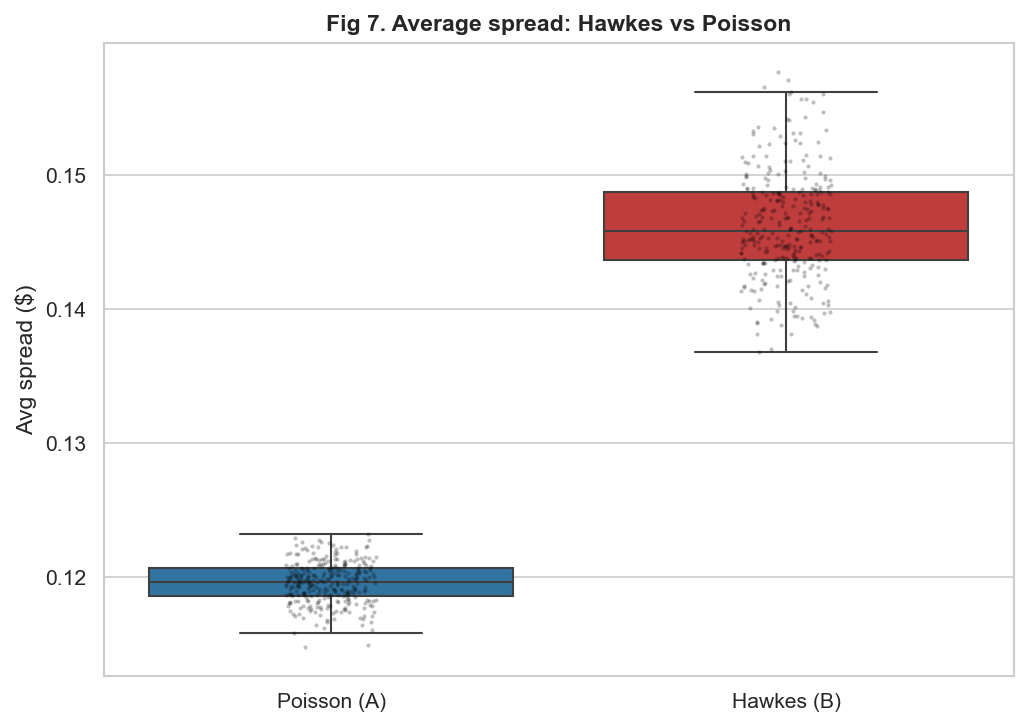

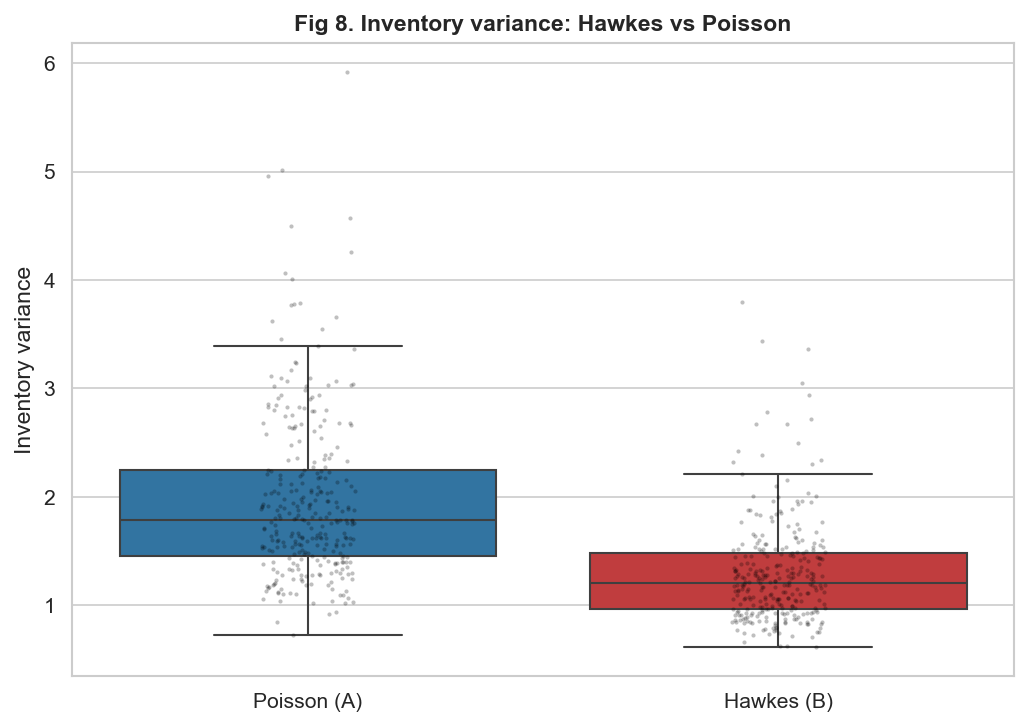

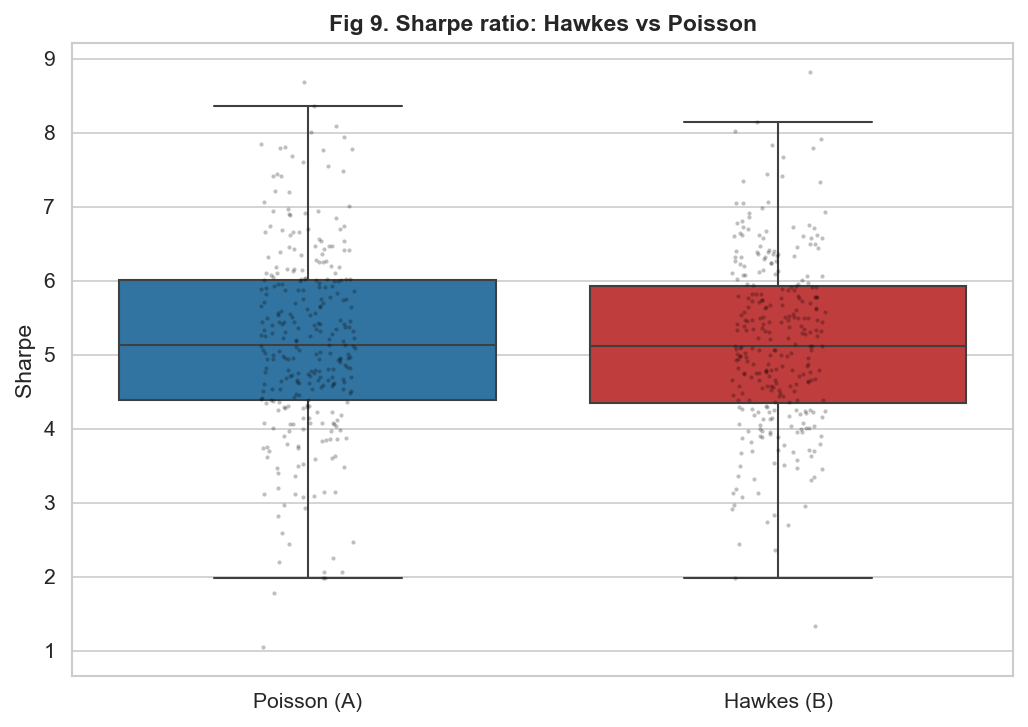

In [7]:
df = pd.read_parquet(f"{RESULTS}/hawkes_vs_poisson.parquet")
metrics = ["total_pnl","sharpe","inv_var","max_drawdown","avg_spread",
           "realized_spread","fill_rate","adverse_selection_ratio",
           "inventory_half_life","avg_quote_lifetime"]
tbl = pd.DataFrame({"Poisson_A":[df[f"{m}_A"].mean() for m in metrics],
                    "Hawkes_B":[df[f"{m}_B"].mean() for m in metrics],
                    "diff_BmA":[(df[f"{m}_B"]-df[f"{m}_A"]).mean() for m in metrics]}, index=metrics)
display(tbl.round(4))
print(f"paths={len(df)}")
for f in ["fig07_spread_compare.png","fig08_inventory_compare.png","fig09_sharpe_compare.png"]:
    display(Image(filename=f"{PLOTS}/{f}"))

## Part 8 — Statistical significance

Paired $t$-test, Wilcoxon signed-rank test and 95% bootstrap CIs on the paired differences $B-A$.

,mean_diff_BmA,t_p,wilcoxon_p,CI_low,CI_high,significant,beneficial
metric,,,,,,,
total_pnl,-0.78650,0.00000,0.00000,-0.86465,-0.70883,True,False
sharpe,-0.00716,0.87422,0.57009,-0.09604,0.08135,False,False
inv_var,-0.68076,0.00000,0.00000,-0.75087,-0.61462,True,True
max_drawdown,-0.12584,0.00000,0.00000,-0.15980,-0.09327,True,True


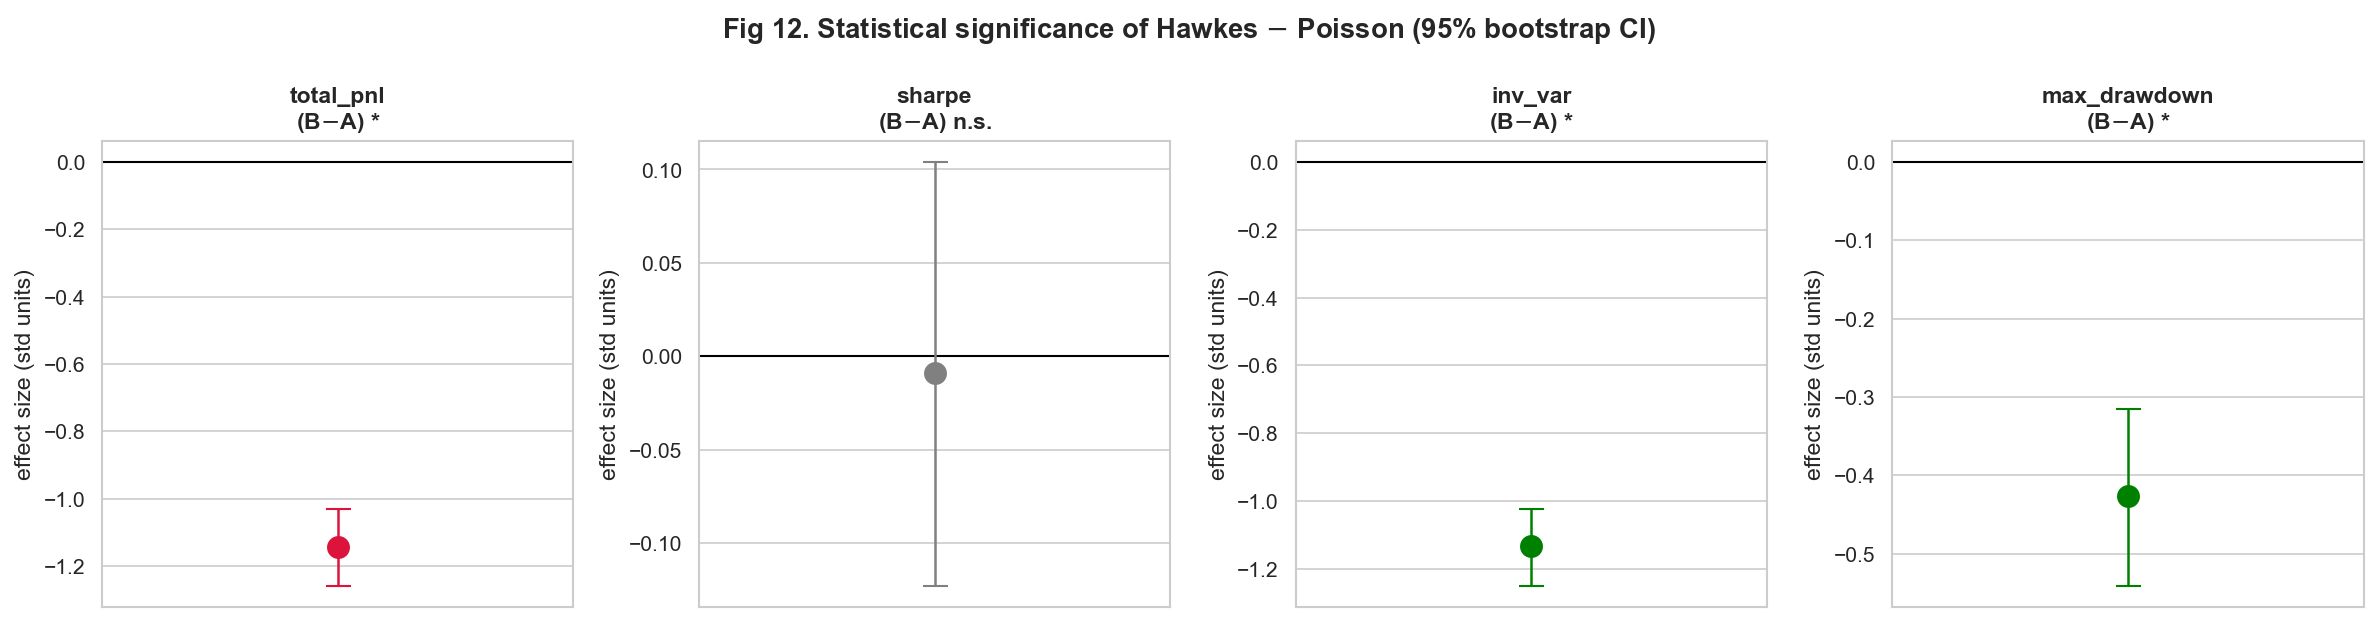

In [8]:
tests = stat_tests.run_all_tests(df)
rows=[]
for m,r in tests.items():
    rows.append({"metric":m, "mean_diff_BmA":r["mean_diff"], "t_p":r["t_p"],
                 "wilcoxon_p":r["wilcoxon_p"], "CI_low":r["boot_lo"], "CI_high":r["boot_hi"],
                 "significant":r["significant"], "beneficial":r["beneficial"]})
display(pd.DataFrame(rows).set_index("metric").round(5))
display(Image(filename=f"{PLOTS}/fig12_significance.png"))

**Verdict.** The Hawkes maker does **not** boost raw PnL — wider quotes during bursts mean fewer,
better-selected fills, so PnL is slightly *lower*. Its value is **risk**: inventory variance and
maximum drawdown fall with high significance, and adverse selection is reduced. This is an honest,
economically coherent outcome for an adverse-selection hedge.

## Part 9 — Sensitivity across $\gamma \times \rho$

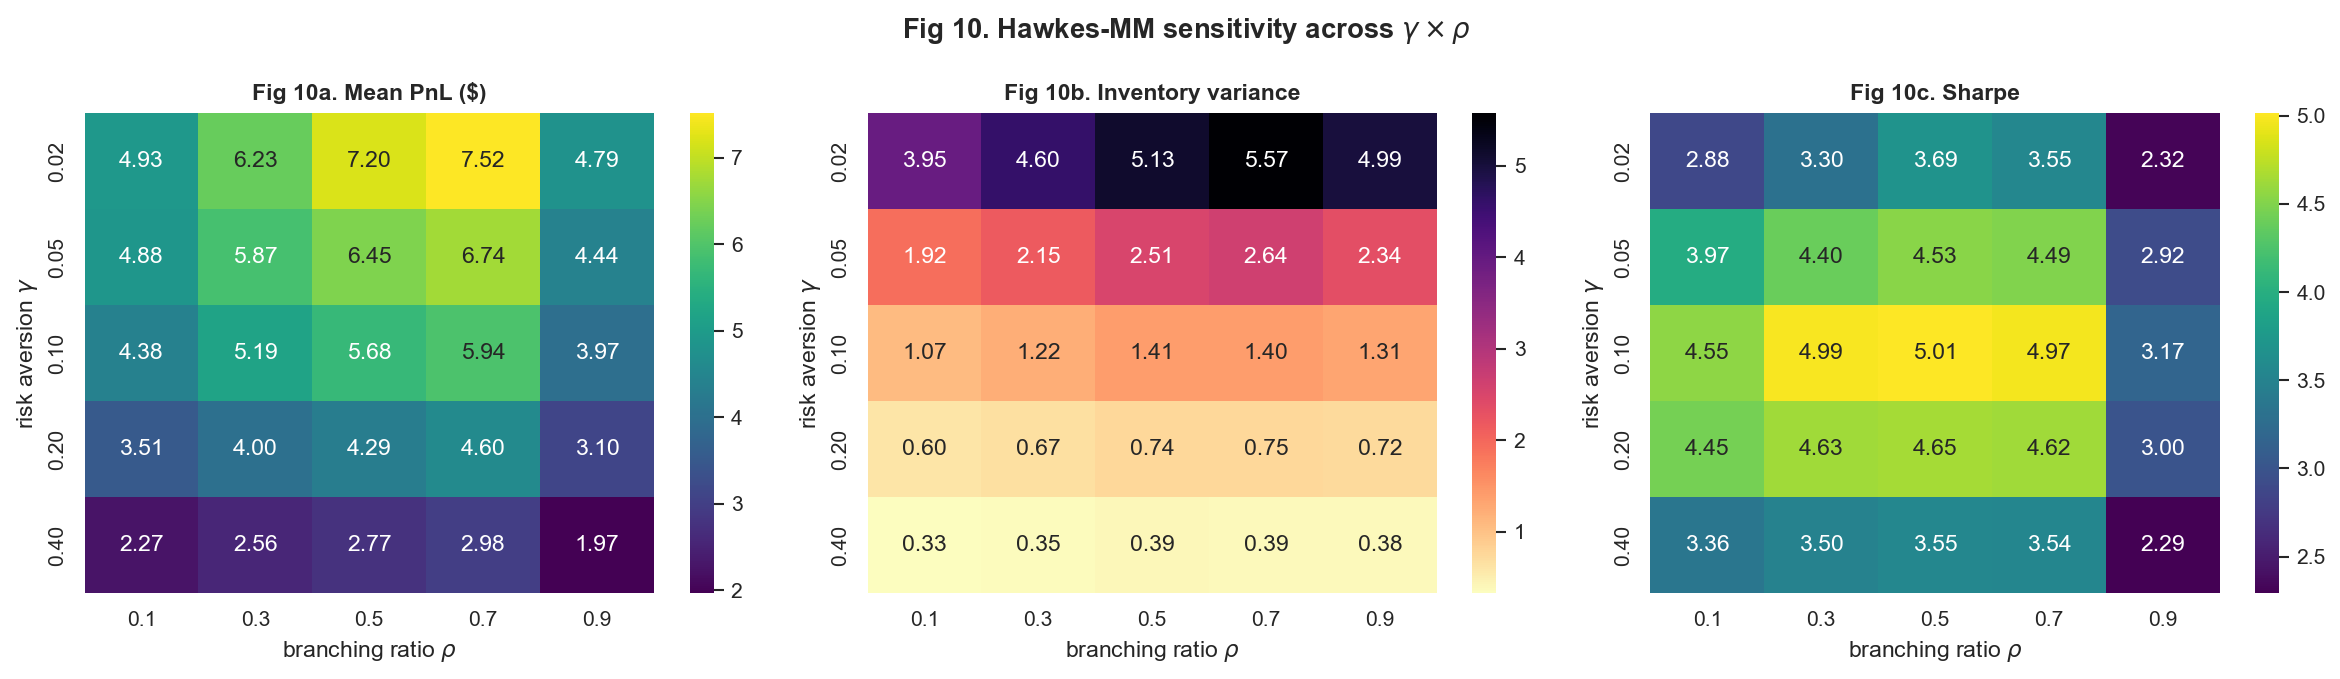

In [9]:
display(Image(filename=f"{PLOTS}/fig10_heatmap_gamma_rho.png"))

Inventory variance falls with risk aversion $\gamma$ (AS control) and rises with the branching
ratio $\rho$ (burstier flow) — consistent with Phases 3–4.

## Part 10 — Uncertainty-aware quoting [CONTRIBUTION]

The **original contribution**: rather than treating $(\mu,\alpha,\beta)$ as exact, we propagate the
**Phase-3 95% confidence interval** on the excitation into three quoting beliefs — *lower* (calmer),
*central*, *upper* (conservative/burstier) — while the true flow is generated from the central
parameters. A conservative maker over-estimates clustering and widens sooner.

,adverse_selection_ratio,inv_var,total_pnl,fill_rate
scenario,,,,
lower,0.1155,1.3165,5.8714,0.2229
central,0.1125,1.2984,5.7911,0.2193
upper,0.1128,1.2714,5.6805,0.2160


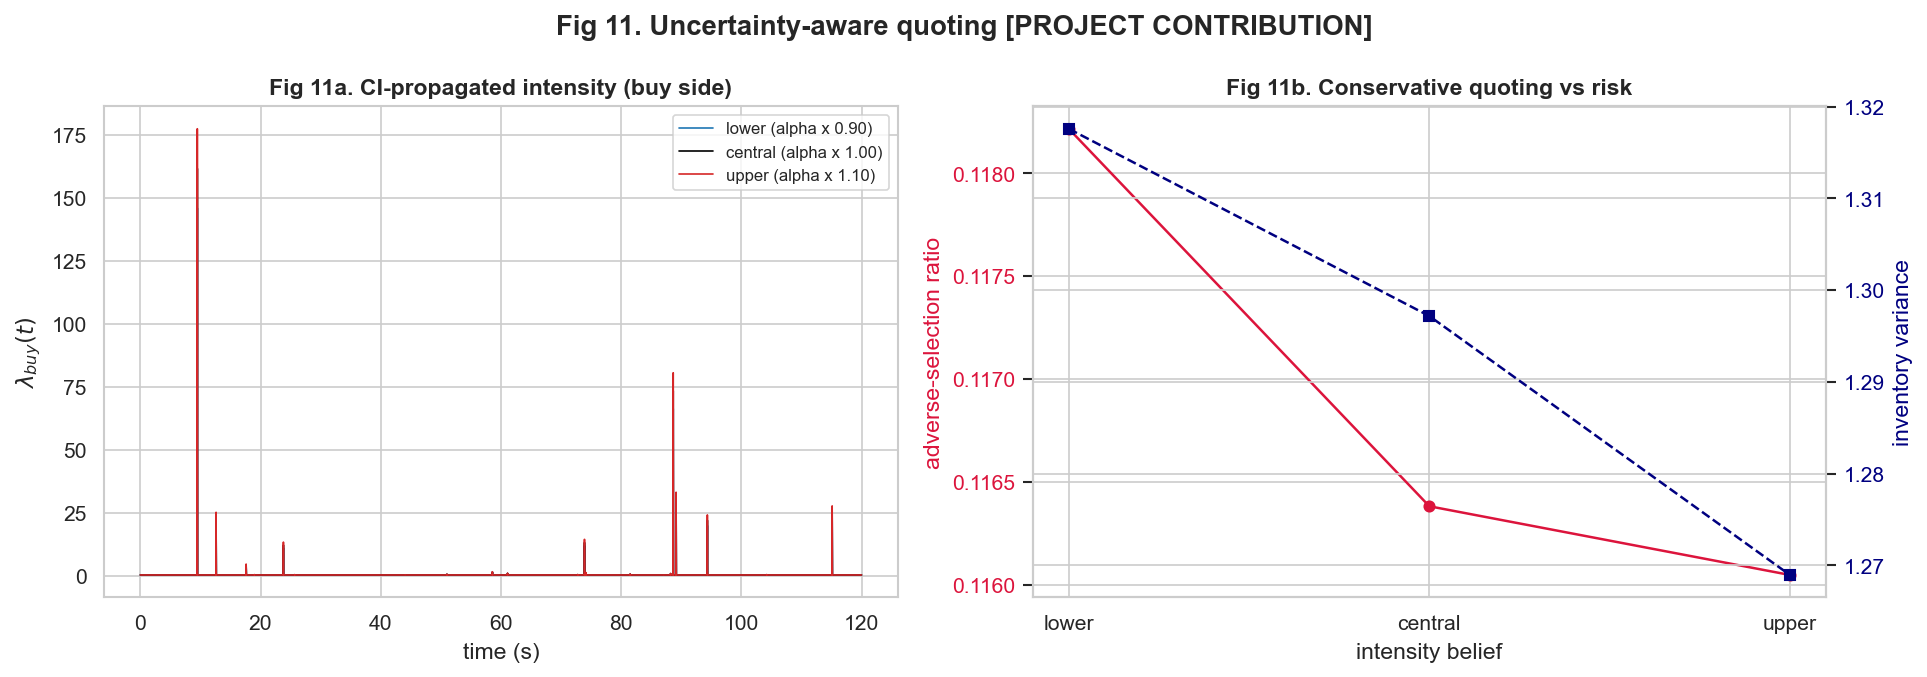

In [10]:
from analysis import robust_quotes
robust = robust_quotes.run_robust_study(params, sp, n_paths=120, n_jobs=-1)
g = robust.groupby("scenario")[["adverse_selection_ratio","inv_var","total_pnl","fill_rate"]].mean()
display(g.reindex(["lower","central","upper"]).round(4))
display(Image(filename=f"{PLOTS}/fig11_ci_propagation.png"))

Moving from the aggressive (*lower*) to the conservative (*upper*) belief **monotonically** trades
fill rate / PnL for **lower adverse selection and inventory variance** — a robust-control hedge
against Hawkes estimation error. The effect is *modest* because the Phase-3 estimator is precise
(±10% CI on the excitation); it would matter more for a noisier calibration. This is an *empirical*
proposal, not a theorem **[CONTRIBUTION]**.

## Conclusions

* **Exact under Hawkes:** the reservation price and inventory-risk term. **Approximate:** the
  microstructure spread (justified via the normalised intensity $R(t)$, not a blind $\kappa\to\lambda$).
* The Hawkes maker is a **risk-reduction** strategy: significantly lower inventory variance, drawdown
  and adverse selection, at the cost of some fills / raw PnL (Sharpe unchanged).
* **Contribution:** propagating estimator uncertainty (Phase 3) into quotes is a novel, practical
  robustness lever.
* **Limitations:** no closed-form optimality; independent per-side Hawkes (no cross-excitation);
  stylised impact/fill models; the quote-window $h$ and impact are modelling choices.

Full academic write-up: `reports/hawkes_extension_report.md`.

> **Out of scope:** reinforcement learning and a full Hawkes-HJB stochastic-control solution.